# Step 3 — which features exist in every 2005–2018 cycle

P_ files (2017–March 2020) are excluded. Run after `step2_leakage.ipynb`; adds to `feature_catalog.csv`:

- `n_cycles_0518`: number of 2005-06 … 2017-18 cycles the (module family, variable) appears in
- `in_all_0518`: feature present in all 7 cycles

A variable is matched by name only within a module family: renamed files are one family (PFC → PFAS, COTNAL → COT), anything else is not, because names collide across modules (LBXHCT = hematocrit in CBC but hydroxycotinine in COT). Nothing is removed here; renamed items (e.g. INDFMINC → INDFMIN2) are not harmonised yet.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

_cwd = Path.cwd().resolve()
ROOT = next((p for p in [_cwd, *_cwd.parents] if (p / "nhanes" / "paths.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("run this notebook from inside the repository")
sys.path.insert(0, str(ROOT))
from nhanes.paths import WORK  # noqa: E402

C7 = ["2005-06", "2007-08", "2009-10", "2011-12", "2013-14", "2015-16", "2017-18"]
FAMILY = {"PFC": "PFAS", "COTNAL": "COT"}

In [2]:
path = WORK / "feature_catalog.csv"
cat = pd.read_csv(path)
lab = pd.read_csv(WORK / "variable_labels.csv")
lab, cat["family"] = lab.assign(family=lab.module.replace(FAMILY)), cat.module.replace(FAMILY)
per_var = lab[lab.cycle.isin(C7)].groupby(["family", "variable"]).cycle.agg(set)
key = pd.MultiIndex.from_frame(cat[["family", "variable"]])
cat["n_cycles_0518"] = [len(per_var.get(k, set())) for k in key]
cat["in_all_0518"] = cat.is_feature & (cat.n_cycles_0518 == 7)
cat.drop(columns="family").to_csv(path, index=False)

f = cat[cat.is_feature & (cat.n_cycles_0518 > 0)].drop_duplicates(["family", "variable"])
per_var = per_var[pd.MultiIndex.from_frame(f[["family", "variable"]])]
all7 = f[f.in_all_0518]
missing = per_var[per_var.map(len) == 6].map(lambda s: (set(C7) - s).pop())
lines = [f"unique feature variables in >=1 of the 7 cycles: {len(f)}", "",
         "by number of cycles present:",
         f.n_cycles_0518.value_counts().sort_index(ascending=False).to_string(), "",
         f"present in all 7 cycles: {len(all7)} (long_format: {int(all7.long_format.sum())})", "",
         "all-7 features by module:",
         all7.groupby("family").size().sort_values(ascending=False).to_string(), "",
         "features in exactly 6 cycles, by the missing cycle:",
         missing.value_counts().to_string(), "",
         "features in all 6 cycles when one cycle is dropped:"]
for drop in C7:
    keep = set(C7) - {drop}
    n = per_var.map(lambda s: keep <= s).sum()
    lines.append(f"  drop {drop}: {n}")
(WORK / "step3_counts.txt").write_text("\n".join(lines) + "\n")
print("\n".join(lines))

unique feature variables in >=1 of the 7 cycles: 1448

by number of cycles present:
n_cycles_0518
7    622
6    112
5     37
4    120
3    128
2    222
1    207

present in all 7 cycles: 622 (long_format: 4)

all-7 features by module:
family
DR1TOT    148
DR2TOT     71
PFQ        34
DUQ        33
MCQ        31
WHQ        31
RHQ        28
BIOPRO     23
CBC        20
DBQ        19
SMQ        19
DEMO       18
DIQ        17
CDQ        16
SMQRTU     15
HIQ        14
KIQ_U      13
BPX        12
BPQ         9
BMX         9
OCQ         8
HSQ         7
HUQ         5
PFAS        5
RXQ_RX      4
HOQ         2
ALB_CR      2
TRIGLY      2
ALQ         1
GHB         1
COT         1
HDL         1
GLU         1
SLQ         1
TCHOL       1

features in exactly 6 cycles, by the missing cycle:
cycle
2017-18    55
2005-06    50
2009-10     7

features in all 6 cycles when one cycle is dropped:
  drop 2005-06: 672
  drop 2007-08: 622
  drop 2009-10: 629
  drop 2011-12: 622
  drop 2013-14: 622
  drop 2015-16

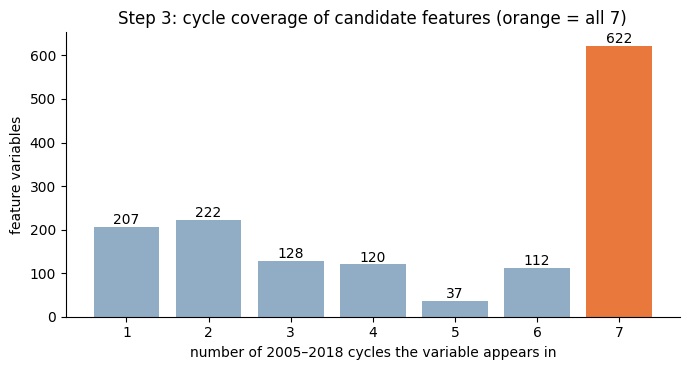

In [3]:
n = f.n_cycles_0518.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(n.index, n.values, color=["#E9783D" if k == 7 else "#91ACC5" for k in n.index])
for k, v in n.items():
    ax.text(k, v + n.max() * 0.01, f"{v:,}", ha="center")
ax.set_xticks(range(1, 8))
ax.set_xlabel("number of 2005–2018 cycles the variable appears in")
ax.set_ylabel("feature variables")
ax.set_title("Step 3: cycle coverage of candidate features (orange = all 7)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()